# Lead Reactivation: Feature Validation Results

Compare **POS** (reactivated after Not Interested) vs **NEG** (never reactivated, NI ≥ 90 days ago).

All outputs are Excel files under `reactivation_analysis/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path("/Users/lekhanigam/RM Feature Analysis/reactivation_analysis")

def load_xlsx(name: str) -> pd.DataFrame:
    path = OUT / f"{name}.xlsx"
    df = pd.read_excel(path)
    print(f"loaded {path.name}: {len(df):,} rows x {df.shape[1]} cols")
    return df

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Output folder:", OUT)

Output folder: /Users/lekhanigam/RM Feature Analysis/reactivation_analysis


## 1. Cohort overview

In [2]:
overview = load_xlsx("cohort_overview")
display(overview)

cross_rows = overview[overview["metric"].astype(str).str.contains("Cross-project", case=False)]
print("\nCross-project snapshot from overview")
display(cross_rows)

print("\nGRAIN: LeadId (leadid) for POS/NEG metrics — NOT MasterLeadId.")
print("Cohort sizes used everywhere below (LeadId counts):")
print("  POS (reactivated): 140,130 leadIds")
print("  NEG (never reactivated): 846,296 leadIds")
print("  Metric tables show counts (yes/n LeadIds) together with percentages.")
print("  Plot columns are POS_% and NEG_% (not POS_pct).")
print("  Cross-project block alone uses unique masterLeadIds (customers spanning projects).")

print(
    "\nInterpretation: About 14% of labeled NI leadIds are POS (reactivated on that journey). "
    "Cross-project counts are additional: same customer NI on one project, later positive on another."
)


loaded cohort_overview.xlsx: 8 rows x 2 cols


,metric,value
0,POS (reactivated),140130.00
1,NEG (never reactivated),846296.00
2,Total labeled,986426.00
3,Reactivation rate %,14.21
4,Cross-project customers (unique MLIDs),153962.00
5,Cross-project NI leads (later positive elsewhere),247811.00
6,Cross-project with project-fit NI (budget/loca...,28876.00
7,% of cross-project NI leads with project-fit r...,11.70



Cross-project snapshot from overview


,metric,value
4,Cross-project customers (unique MLIDs),153962.0
5,Cross-project NI leads (later positive elsewhere),247811.0
6,Cross-project with project-fit NI (budget/loca...,28876.0
7,% of cross-project NI leads with project-fit r...,11.7



Cohort sizes used everywhere below:
  POS (reactivated): 140,130 leads
  NEG (never reactivated): 846,296 leads
  Metric tables show counts (yes/n) together with percentages.

Interpretation: About 14% of labeled NI leads are POS (reactivated on that journey). Cross-project counts are additional: same customer NI on one project, later positive on another.


loaded summary_by_project.xlsx: 7 rows x 7 cols
Per project: leads (total), POS count, NEG count, POS_% / NEG_%


,project_name,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct
0,Loft,292271,48796,243475,16.70,83.30,16.70
1,Landmark,182235,22087,160148,12.12,87.88,12.12
2,Broadway,162106,23791,138315,14.68,85.32,14.68
3,Spectra,150719,21864,128855,14.51,85.49,14.51
4,Springs,126947,13186,113761,10.39,89.61,10.39
5,Spire,58639,4410,54229,7.52,92.48,7.52
6,Legacy,13509,5996,7513,44.39,55.61,44.39


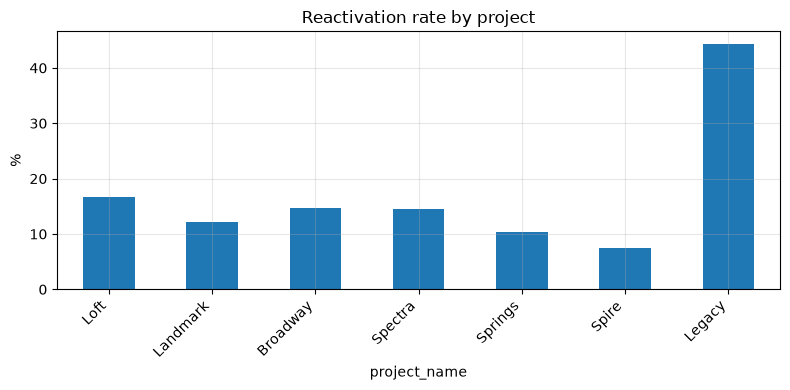

Interpretation: Reactivation rate differs by project — project must be controlled when scoring leads.


In [3]:
by_project = load_xlsx("summary_by_project")
print("Per project: LeadId totals, POS / NEG LeadId counts, POS_% / NEG_%")
display(by_project)

ax = by_project.set_index("project_name")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by project", ylabel="%"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Interpretation: Reactivation rate differs by project — project must be controlled when scoring leads.")


### Cross-project reactivation (after project split)

Same customer (`masterLeadId`) went **Not Interested on project A**, then later reached a **positive (non-NI) stage on a different project B**.

**Project-fit NI** = budget / location / availability / vastu.


Cross-project headline numbers


,metric,value
0,Cross-project pairs (NI lead × later positive ...,724189.0
1,Unique masterLeadIds with cross-project return,153962.0
2,Unique NI leads that later went positive on an...,247811.0
3,"Of those, NI due to budget/location/availabili...",28876.0
4,% of cross-project NI leads with project-fit r...,11.7



Top project A → project B flows (all cross-project returns)


,ni_project,positive_project,ni_leads
0,SPECTRA,LOFT,19447
1,LOFT,BROADWAY,18184
2,LOFT,LANDMARK,17058
3,BROADWAY,LOFT,15891
4,LANDMARK,LOFT,14541
5,LANDMARK,BROADWAY,13760
6,LOFT,SPECTRA,11968
7,SPECTRA,BROADWAY,11956
8,SPRINGS,LOFT,9690
9,SPECTRA,LANDMARK,8783


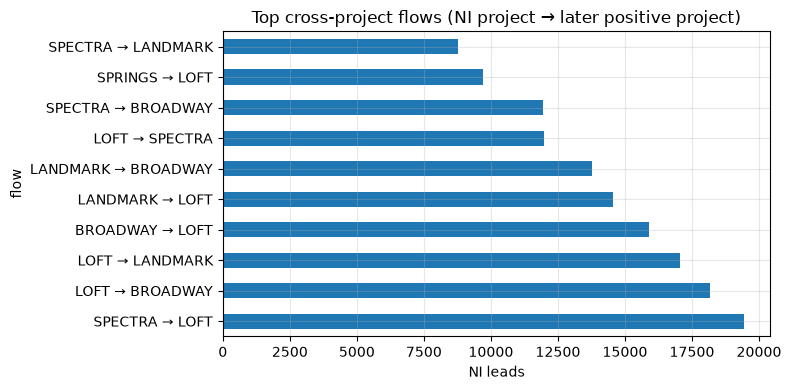


Project-fit NI only (budget / location / availability / vastu) — flows


,ni_project,positive_project,ni_leads
0,LOFT,LANDMARK,2105
1,SPECTRA,LOFT,1784
2,LOFT,BROADWAY,1730
3,LANDMARK,LOFT,1677
4,LANDMARK,BROADWAY,1634
5,BROADWAY,LOFT,1623
6,SPRINGS,LOFT,1473
7,LOFT,SPECTRA,1304
8,LOFT,SPRINGS,1023
9,SPECTRA,BROADWAY,1021


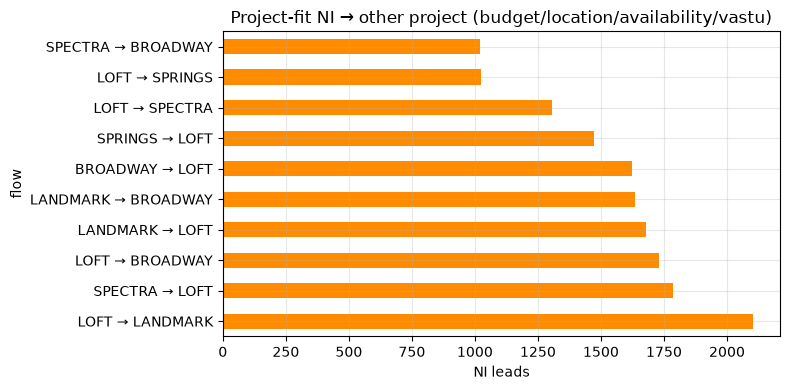


Reasons among project-fit cross-project returns


,reason_label,ni_leads
0,Budget,14132
1,Location,8587
2,Availability,1609
3,Data Migration,962
4,Price,936
5,Others,672
6,Not looking for Property,651
7,Casual Enquiry,287
8,Unit Size,239
9,Handover Timeline,195



Landing stage on the other project


,positive_stage,ni_leads
0,New Lead,22441
1,Lead Initiated,4613
2,Pre Site Visit,937
3,Post Site Visit,832
4,Flat Blocked,33
5,Sales Closure,20



Interpretation: 153,962 customers returned on a different project after NI elsewhere.
Of the unique NI leads in those journeys, 28,876 had project-fit reasons (budget/location/availability/vastu) — strong candidates for cross-sell / project switch plays.


In [4]:
cross_overview = pd.read_excel(OUT / "cross_project_reactivation.xlsx", sheet_name="1_Overview")
flows = pd.read_excel(OUT / "cross_project_reactivation.xlsx", sheet_name="2_Flows_All")
fit_flows = pd.read_excel(OUT / "cross_project_reactivation.xlsx", sheet_name="3_Flows_ProjectFit_NI")
fit_reasons = pd.read_excel(OUT / "cross_project_reactivation.xlsx", sheet_name="4_ProjectFit_Reasons")
fit_stages = pd.read_excel(OUT / "cross_project_reactivation.xlsx", sheet_name="5_Landing_Stages")

print("Cross-project headline numbers")
display(cross_overview)

print("\nTop project A → project B flows (all cross-project returns)")
display(flows.head(15))

top_flows = flows.head(10).copy()
top_flows["flow"] = top_flows["ni_project"].astype(str) + " → " + top_flows["positive_project"].astype(str)
top_flows.set_index("flow")["ni_leads"].plot(
    kind="barh", title="Top cross-project flows (NI project → later positive project)"
)
plt.xlabel("NI leads"); plt.tight_layout(); plt.show()

print("\nProject-fit NI only (budget / location / availability / vastu) — flows")
display(fit_flows.head(15))

fit_top = fit_flows.head(10).copy()
fit_top["flow"] = fit_top["ni_project"].astype(str) + " → " + fit_top["positive_project"].astype(str)
fit_top.set_index("flow")["ni_leads"].plot(
    kind="barh", title="Project-fit NI → other project (budget/location/availability/vastu)", color="darkorange"
)
plt.xlabel("NI leads"); plt.tight_layout(); plt.show()

print("\nReasons among project-fit cross-project returns")
display(fit_reasons.head(15))

print("\nLanding stage on the other project")
display(fit_stages.head(12))

n_mlid = int(cross_overview.loc[cross_overview["metric"].str.contains("masterLeadIds"), "value"].iloc[0])
n_fit = int(cross_overview.loc[cross_overview["metric"].str.contains("budget/location"), "value"].iloc[0])
print(f"\nInterpretation: {n_mlid:,} customers returned on a different project after NI elsewhere.")
print(f"Of the unique NI leads in those journeys, {n_fit:,} had project-fit reasons (budget/location/availability/vastu) — strong candidates for cross-sell / project switch plays.")


## 2. Which features separate POS vs NEG?

loaded feature_comparison.xlsx: 6 rows x 8 cols
Cohort: POS n=140,130 | NEG n=846,296
POS_yes/POS_n and NEG_yes/NEG_n are absolute counts; % is share of that cohort.


,feature,POS,NEG,diff_pp
0,Any call after NI (within 90d),"35,596 / 140,130 (25.4%)","42,524 / 846,296 (5.0%)",20.4
1,Inbound call after NI,"23,534 / 140,130 (16.8%)","13,834 / 846,296 (1.6%)",15.2
2,Website visit after NI,"8,377 / 140,130 (6.0%)","2,156 / 846,296 (0.3%)",5.7
3,WhatsApp inbound after NI,"15,273 / 140,130 (10.9%)","51,357 / 846,296 (6.1%)",4.8
4,Pre Site Visit before NI,"10,463 / 140,130 (7.5%)","31,610 / 846,296 (3.7%)",3.7
5,Post Site Visit before NI,"5,917 / 140,130 (4.2%)","16,058 / 846,296 (1.9%)",2.3


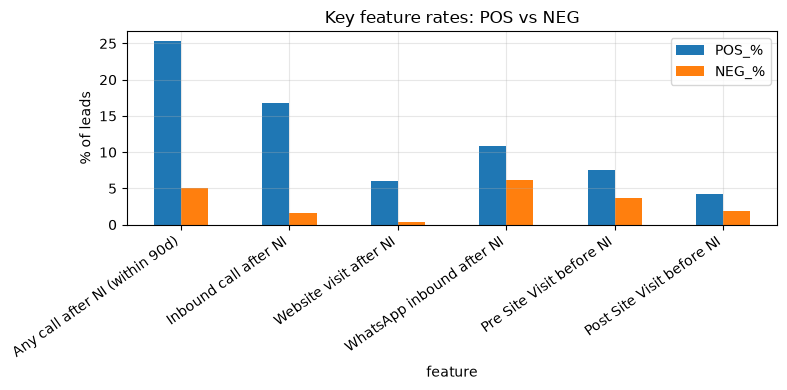

Interpretation: Post-NI inbound calls and any post-NI call show the largest gaps. Prior site-visit depth and post-NI web/WA inbound also help.


In [5]:
feat = load_xlsx("feature_comparison")
print("Cohort (LeadId): POS n=140,130 | NEG n=846,296")
print("POS_yes/POS_n and NEG_yes/NEG_n are LeadId counts; % is share of that cohort.")
view = feat.copy()
view["POS"] = view.apply(lambda r: f"{int(r.POS_yes):,} / {int(r.POS_n):,} ({r['POS_%']}%)", axis=1)
view["NEG"] = view.apply(lambda r: f"{int(r.NEG_yes):,} / {int(r.NEG_n):,} ({r['NEG_%']}%)", axis=1)
display(view[["feature", "POS", "NEG", "diff_pp"]])

plot_df = feat.set_index("feature")[["POS_%", "NEG_%"]]
plot_df.plot(kind="bar", title="Key feature rates: POS vs NEG (LeadId %)", ylabel="% of leadIds")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Interpretation: Post-NI inbound calls and any post-NI call show the largest gaps. Prior site-visit depth and post-NI web/WA inbound also help.")


## 3. Stage & NI reason

loaded summary_by_stage.xlsx: 5 rows x 7 cols
Per stage-before-NI: total leads, POS count, NEG count


,stage_before_ni,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct
0,Flat Blocked,706,321,385,45.47,54.53,45.47
1,Post Site Visit,21408,5657,15751,26.42,73.58,26.42
2,Pre Site Visit,31667,6947,24720,21.94,78.06,21.94
3,Lead Initiated,317665,52901,264764,16.65,83.35,16.65
4,New Lead,614560,74183,540377,12.07,87.93,12.07


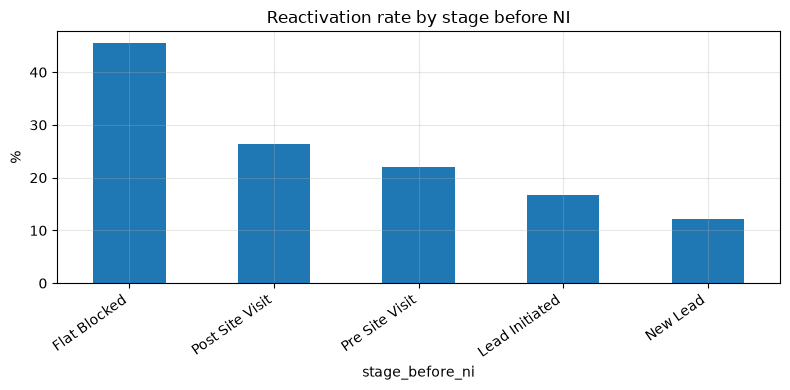

Interpretation: Leads that reached Post/Pre Site Visit before dropping to NI come back more often than New Lead drops.


In [6]:
by_stage = load_xlsx("summary_by_stage")
print("Per stage-before-NI: total leads, POS count, NEG count")
display(by_stage)

by_stage.set_index("stage_before_ni")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by stage before NI", ylabel="%"
)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Interpretation: Leads that reached Post/Pre Site Visit before dropping to NI come back more often than New Lead drops.")


loaded summary_by_ni_tier.xlsx: 4 rows x 7 cols
Per NI reason tier: total leads, POS count, NEG count


,ni_reason_tier,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct
0,SOFT,42339,8680,33659,20.50,79.50,20.50
1,MEDIUM,833189,121455,711734,14.58,85.42,14.58
2,HARD,5725,800,4925,13.97,86.03,13.97
3,SYSTEM,105173,9195,95978,8.74,91.26,8.74


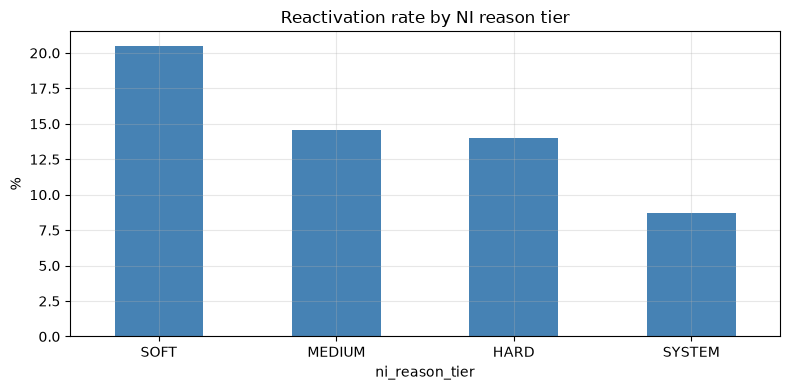

Interpretation: Soft reasons (budget/timing/etc.) reactivate more than hard/system reasons. NI reason tier is a Keep feature.


In [7]:
by_tier = load_xlsx("summary_by_ni_tier")
print("Per NI reason tier: total leads, POS count, NEG count")
display(by_tier)

by_tier.set_index("ni_reason_tier")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by NI reason tier", ylabel="%", color="steelblue"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Interpretation: Soft reasons (budget/timing/etc.) reactivate more than hard/system reasons. NI reason tier is a Keep feature.")


## 4. Call analysis

Post-NI window = from NI until min(NI+90 days, reactivation).


Cohort: POS n=140,130 | NEG n=846,296
POS vs NEG call rates (counts + %)


,feature,POS,NEG,diff_pp
0,Any call after NI (≤90d),"35,596 / 140,130 (25.4%)","42,524 / 846,296 (5.0%)",20.4
1,Inbound call after NI,"23,534 / 140,130 (16.8%)","13,834 / 846,296 (1.6%)",15.2
2,Any call before NI,"133,821 / 140,130 (95.5%)","795,900 / 846,296 (94.0%)",1.5


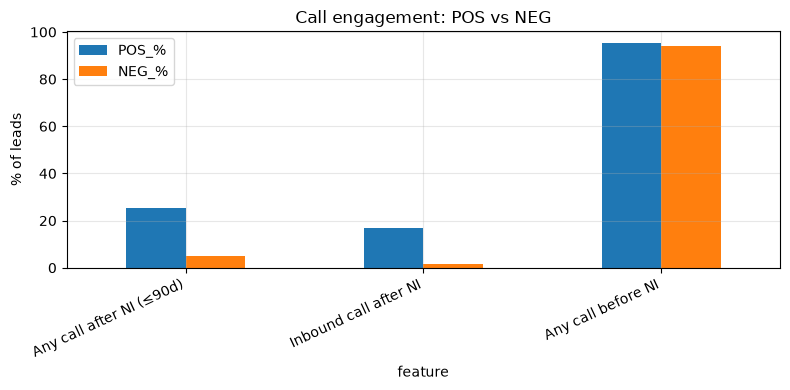

Numeric call stats (n = non-null leads in cohort)


,metric,cohort,n,median,mean,pct_zero
0,Calls before NI,POS,140130,4,5.40,4.5
1,Calls before NI,NEG,846296,3,4.31,6.0
2,Calls after NI,POS,140130,0,0.33,74.6
3,Calls after NI,NEG,846296,0,0.07,95.0
4,Inbound calls after NI,POS,140130,0,0.19,83.2
5,Inbound calls after NI,NEG,846296,0,0.02,98.4
6,Days since last call,POS,134269,30,46.34,33.2
7,Days since last call,NEG,796687,90,94.52,5.9


Interpretation: Post-NI calls — especially inbound — strongly separate POS from NEG. Pre-NI calling is nearly universal and weak as a discriminator.


In [8]:
call_rates = pd.read_excel(OUT / "channel_call_analysis.xlsx", sheet_name="Rates")
call_num = pd.read_excel(OUT / "channel_call_analysis.xlsx", sheet_name="Numeric")
print("Cohort (LeadId): POS n=140,130 | NEG n=846,296")
print("POS vs NEG call rates (LeadId counts + %)")
view = call_rates.copy()
view["POS"] = view.apply(lambda r: f"{int(r.POS_yes):,} / {int(r.POS_n):,} ({r['POS_%']}%)", axis=1)
view["NEG"] = view.apply(lambda r: f"{int(r.NEG_yes):,} / {int(r.NEG_n):,} ({r['NEG_%']}%)", axis=1)
display(view[["feature", "POS", "NEG", "diff_pp"]])

call_rates.set_index("feature")[["POS_%", "NEG_%"]].plot(
    kind="bar", title="Call engagement: POS vs NEG", ylabel="% of leadIds"
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

print("Numeric call stats (n = non-null leadIds in cohort)")
display(call_num)

print("Interpretation: Post-NI calls — especially inbound — strongly separate POS from NEG. Pre-NI calling is nearly universal and weak as a discriminator.")


## 5. Website analysis


Cohort: POS n=140,130 | NEG n=846,296
POS vs NEG website rates (counts + %)


,feature,POS,NEG,diff_pp
0,Any website session after NI,"8,377 / 140,130 (6.0%)","2,156 / 846,296 (0.3%)",5.7
1,Viewed price / price sheet,"53,471 / 140,130 (38.2%)","366,970 / 846,296 (43.4%)",-5.2
2,Any website session before NI,"50,276 / 140,130 (35.9%)","365,518 / 846,296 (43.2%)",-7.3


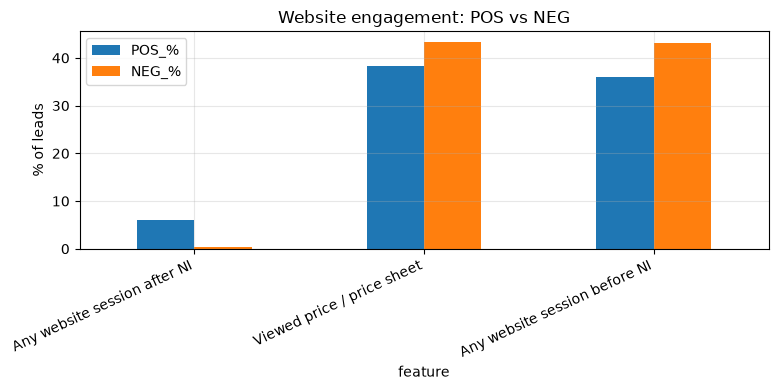

Interpretation: Returning to the website after NI is rare but much more common among POS. Pre-NI browsing / price views are higher in NEG — treat as confounding/coverage, not a chase signal.


In [9]:
web_rates = pd.read_excel(OUT / "channel_website_analysis.xlsx", sheet_name="Rates")
print("Cohort (LeadId): POS n=140,130 | NEG n=846,296")
print("POS vs NEG website rates (LeadId counts + %)")
view = web_rates.copy()
view["POS"] = view.apply(lambda r: f"{int(r.POS_yes):,} / {int(r.POS_n):,} ({r['POS_%']}%)", axis=1)
view["NEG"] = view.apply(lambda r: f"{int(r.NEG_yes):,} / {int(r.NEG_n):,} ({r['NEG_%']}%)", axis=1)
display(view[["feature", "POS", "NEG", "diff_pp"]])

web_rates.set_index("feature")[["POS_%", "NEG_%"]].plot(
    kind="bar", title="Website engagement: POS vs NEG", ylabel="% of leadIds"
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

print("Interpretation: Returning to the website after NI is rare but much more common among POS. Pre-NI browsing / price views are higher in NEG — treat as confounding/coverage, not a chase signal.")


## 6. WhatsApp analysis


Cohort: POS n=140,130 | NEG n=846,296
POS vs NEG WhatsApp rates (counts + %)


,feature,POS,NEG,diff_pp
0,User WhatsApp inbound after NI,"15,273 / 140,130 (10.9%)","51,357 / 846,296 (6.1%)",4.8
1,Any WhatsApp message after NI,"96,113 / 140,130 (68.6%)","778,462 / 846,296 (92.0%)",-23.4


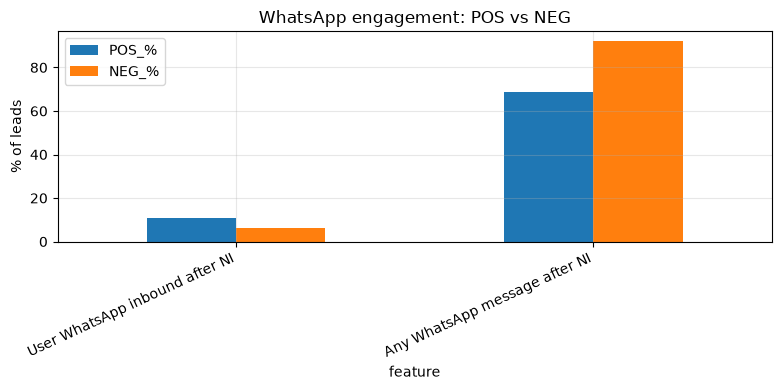

Interpretation: Prefer user inbound WhatsApp after NI (+4.8 pp). Total WA volume is higher for NEG — likely automation/templates — so do not use raw WA count as a positive signal.


In [10]:
wa_rates = pd.read_excel(OUT / "channel_whatsapp_analysis.xlsx", sheet_name="Rates")
print("Cohort (LeadId): POS n=140,130 | NEG n=846,296")
print("POS vs NEG WhatsApp rates (LeadId counts + %)")
view = wa_rates.copy()
view["POS"] = view.apply(lambda r: f"{int(r.POS_yes):,} / {int(r.POS_n):,} ({r['POS_%']}%)", axis=1)
view["NEG"] = view.apply(lambda r: f"{int(r.NEG_yes):,} / {int(r.NEG_n):,} ({r['NEG_%']}%)", axis=1)
display(view[["feature", "POS", "NEG", "diff_pp"]])

wa_rates.set_index("feature")[["POS_%", "NEG_%"]].plot(
    kind="bar", title="WhatsApp engagement: POS vs NEG", ylabel="% of leadIds"
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

print("Interpretation: Prefer user inbound WhatsApp after NI (+4.8 pp). Total WA volume is higher for NEG — likely automation/templates — so do not use raw WA count as a positive signal.")


## 7. Feature scorecard (Keep / Modify / Remove)

In [11]:
score = load_xlsx("feature_scorecard")
score = score.sort_values(["verdict", "diff_pp"], ascending=[True, False])
display(score)

print("\nKeep count:", (score["verdict"] == "Keep").sum())
print("Modify count:", (score["verdict"] == "Modify").sum())
print("Remove count:", (score["verdict"] == "Remove").sum())

loaded feature_scorecard.xlsx: 23 rows x 6 cols


,feature,category,coverage,diff_pp,verdict,note
7,bornsource,stage,1.000,63.66,Keep,source rate spread
12,days_since_last_call,call,0.944,60.00,Keep,median POS 30.0 vs NEG 90.0 (lower = more recent)
5,stage_before_ni,stage,1.000,33.40,Keep,prior stage rate spread
9,any_post_ni_call,call,1.000,20.38,Keep,Any call in post-NI window
10,any_post_ni_inbound,call,1.000,15.16,Keep,Inbound call in post-NI window
11,pre_ni_calls,call,1.000,10.16,Keep,more than equal to 5 calls before NI
4,ni_reason_tier,stage,1.000,6.53,Keep,SOFT 20.5% vs HARD 14.0%
16,any_post_web,website,0.483,5.72,Keep,Web session in post-NI window
21,any_post_wa_inbound,whatsapp,1.000,4.83,Keep,User WA inbound in post-NI window
0,had_pre_before_ni,stage,1.000,3.73,Keep,Pre Site Visit before NI



Keep count: 15
Modify count: 4
Remove count: 4


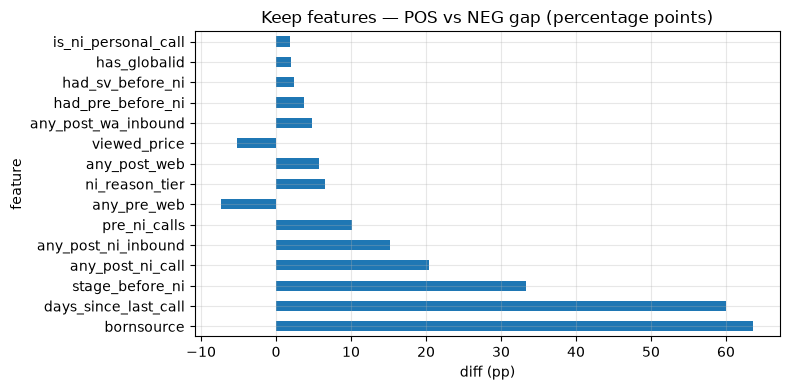

Top Keep signals for the model:
  • bornsource: +63.7 pp — source rate spread
  • days_since_last_call: +60.0 pp — median POS 30.0 vs NEG 90.0 (lower = more recent)
  • stage_before_ni: +33.4 pp — prior stage rate spread
  • any_post_ni_call: +20.4 pp — Any call in post-NI window
  • any_post_ni_inbound: +15.2 pp — Inbound call in post-NI window
  • pre_ni_calls: +10.2 pp — more than equal to 5 calls before NI
  • any_pre_web: -7.3 pp — Web session before NI (NEG higher â interpret carefully)
  • ni_reason_tier: +6.5 pp — SOFT 20.5% vs HARD 14.0%


In [12]:
keep = score[score["verdict"] == "Keep"].copy()
keep = keep.sort_values("diff_pp", key=lambda s: s.abs(), ascending=False)

ax = keep.set_index("feature")["diff_pp"].plot(
    kind="barh", title="Keep features — POS vs NEG gap (percentage points)", xlabel="diff (pp)"
)
plt.tight_layout()
plt.show()

print("Top Keep signals for the model:")
for _, r in keep.head(8).iterrows():
    print(f"  • {r['feature']}: {r['diff_pp']:+.1f} pp — {r['note']}")

## 8. NI reason tier definitions

Order: **SYSTEM → HARD → SOFT → MEDIUM (default)**.

| Tier | Rule |
|------|------|
| **SYSTEM** | Exact reason: Data Migration; Flow Builder; Not Interested From Dashboard; Moving leads before 2024… |
| **HARD** | Keywords in reason/comments: wrong number, not eligible, already booked, duplicate, invalid |
| **SOFT** | Keywords in reason/comments: budget, later, follow, possession, location, considering, thinking |
| **MEDIUM** | Everything else (Post Call, Personal Call, etc.) |

See `ni_reason_tier_mapping.xlsx` for the full list.


In [13]:
print("Assignment rules")
display(pd.read_excel(OUT / "ni_reason_tier_mapping.xlsx", sheet_name="1_Rules"))
print("\nSYSTEM reasons")
display(pd.read_excel(OUT / "ni_reason_tier_mapping.xlsx", sheet_name="3_SYSTEM_Reasons"))
print("\nCommon MEDIUM reasons")
display(pd.read_excel(OUT / "ni_reason_tier_mapping.xlsx", sheet_name="4_MEDIUM_Common_Reasons"))
print("\nTier volumes")
display(pd.read_excel(OUT / "ni_reason_tier_mapping.xlsx", sheet_name="2_Tier_Counts"))


Assignment rules


,tier,how_assigned,match_values_or_keywords
0,SYSTEM,Exact match on NI reason field,Data Migration
1,SYSTEM,Exact match on NI reason field,Lead moved to Not Interested by Flow Builder
2,SYSTEM,Exact match on NI reason field,Not Interested From Dashboard
3,SYSTEM,Exact match on NI reason field,Moving leads before 2024 to Not Interested
4,HARD,Keyword in NI reason OR comments (case-insensi...,wrong number
5,HARD,Keyword in NI reason OR comments (case-insensi...,not eligible
6,HARD,Keyword in NI reason OR comments (case-insensi...,already booked
7,HARD,Keyword in NI reason OR comments (case-insensi...,duplicate
8,HARD,Keyword in NI reason OR comments (case-insensi...,invalid
9,SOFT,Keyword in NI reason OR comments (case-insensi...,budget



SYSTEM reasons


,first_ni_reason,leads,tier
0,Data Migration,87007,SYSTEM
1,Lead moved to Not Interested by Flow Builder,10277,SYSTEM
2,Not Interested From Dashboard,6799,SYSTEM
3,Moving leads before 2024 to Not Interested,1090,SYSTEM



Common MEDIUM reasons


,first_ni_reason,leads,tier
0,Post Call,509551,MEDIUM
1,Multiple Call Fails by Customer,201132,MEDIUM
2,Personal Call,117982,MEDIUM
3,Lead Closed By Voiz,22199,MEDIUM
4,Whatsapp Inbound,13011,MEDIUM
5,Converting CP lead to ASBL DB,6059,MEDIUM
6,Executive InActive,4591,MEDIUM
7,On Site Visit,2939,MEDIUM
8,Executive Referral,1569,MEDIUM
9,Flat Cancelled,968,MEDIUM



Tier volumes


,ni_reason_tier,leads,reactivated,reactivation_rate_pct
0,SOFT,42339,8680,20.50
1,MEDIUM,833189,121455,14.58
2,HARD,5725,800,13.97
3,SYSTEM,105173,9195,8.74


## 9. Business takeaways

1. **Prioritize post-NI engagement** - inbound calls and any call in the 90-day window are the strongest separators.
2. **Funnel depth before NI matters** - Pre/Post Site Visit and stage-before-NI separate POS from NEG.
3. **NI reason quality matters** - soft reasons return more often than hard/system reasons.
4. **Project and born source differ a lot** - use as controls / features, not ignored.
5. **Avoid raw oscillator flag** - 2+ NI events mostly reflects post-reactivation history (leakage). Rebuild as prior-cycle-only.
6. **Prefer WA inbound over total WA** - total WA is inflated by automation on NEG leads.

7. **Cross-project returns are real** - many customers NI on one project (often budget/location/availability/vastu) and later go positive on another; use for project-switch offers.

### Excel files
- `reactivation_analysis_report.xlsx` - overview + scorecard + summaries (share this)
- `analysis_final.xlsx` - lead-level table with readable names
- `feature_scorecard.xlsx` - Keep/Modify/Remove decisions
- `channel_call_analysis.xlsx` / `channel_website_analysis.xlsx` / `channel_whatsapp_analysis.xlsx`
- `cross_project_reactivation.xlsx` — cross-project return numbers and flows
